In [ ]:
from google.colab import drive # importa biblioteca que se conecta no google drive
drive.mount('/content/drive') # monta o google drive

Mounted at /content/drive


In [ ]:
# importar as bibliotecas de manipulação de dados
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# importar as bibliotecas de machine learning
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [ ]:
input_file = '/content/drive/MyDrive/dados_reator_quimico.csv'

df = pd.read_csv(input_file) # importa o arquivo csv do google drive

print('Amostra dos dados importados:')
display(df.head()) # mostra as primeiras linhas do csv importado como dataframe

Amostra dos dados importados:


,Pressao_bar,Temperatura_C
0,91.74,193.55
1,31.67,18.14
2,115.35,176.91
3,5.77,315.90
4,29.24,367.20


In [ ]:
x_data = df.select_dtypes(include=[np.number,float,int])
display(x_data)

,Pressao_bar,Temperatura_C
0,91.74,193.55
1,31.67,18.14
2,115.35,176.91
3,5.77,315.90
4,29.24,367.20
...,...,...
1195,27.91,338.60
1196,13.52,31.09
1197,20.34,32.77
1198,14.92,6.34


In [ ]:
# escalona os dados para que o modelo não apresente falha de inferência
scaler = StandardScaler()
x_data_scaled = scaler.fit_transform(x_data)

In [ ]:
values = []
k_values = range(1,11)

print("Calculando o k ideal com o Método do Cotovelo:")
for k in k_values:
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  kmeans.fit(x_data_scaled)
  values.append(kmeans.inertia_)

Calculando o k ideal com o Método do Cotovelo:


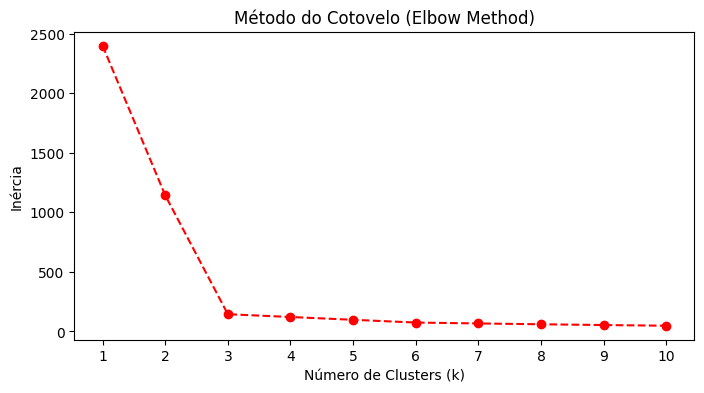

In [ ]:
plt.figure(figsize=(8,4))
plt.plot(k_values, values, marker='o', linestyle='--', color='red')
plt.title('Método do Cotovelo (Elbow Method)')
plt.xlabel('Número de Clusters (k)')
plt.ylabel('Inércia')
plt.xticks(k_values)
plt.show()

In [ ]:
# define qual o k a ser usado baseado no método do cotovelo, e cria novamente o modelo
k_used = 3
model = KMeans(n_clusters=k_used, random_state=42, n_init=10)

groups = model.fit_predict(x_data_scaled)
print(f'Grupos criados: {groups}')
df['Group'] = groups
display(df.head())

Grupos criados: [1 0 1 ... 0 0 2]


,Pressao_bar,Temperatura_C,Group
0,91.74,193.55,1
1,31.67,18.14,0
2,115.35,176.91,1
3,5.77,315.90,2
4,29.24,367.20,2


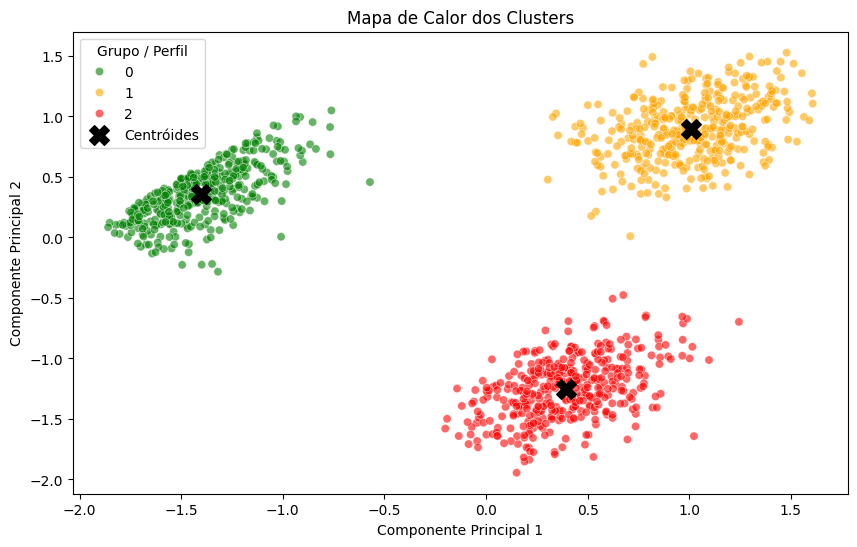

In [ ]:
pca = PCA(n_components=2)
x_2d = pca.fit_transform(x_data_scaled)

plt.figure(figsize=(10, 6))
sns.scatterplot(x=x_2d[:,0], y=x_2d[:,1], hue=df['Group'],
                palette=['green','orange','red'],alpha=0.6)
points_2d = pca.transform(model.cluster_centers_)
plt.scatter(points_2d[:,0], points_2d[:,1], c='black', marker='X', s=200, label='Centróides')
plt.title('Mapa de Calor dos Clusters')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend(title='Grupo / Perfil')
plt.show()

In [ ]:
score = silhouette_score(x_data_scaled, groups)
print(f'Score de Silhueta: {score}')

Score de Silhueta: 0.8075599887246216
